In [5]:
import matplotlib.pyplot as plt
from granad import *

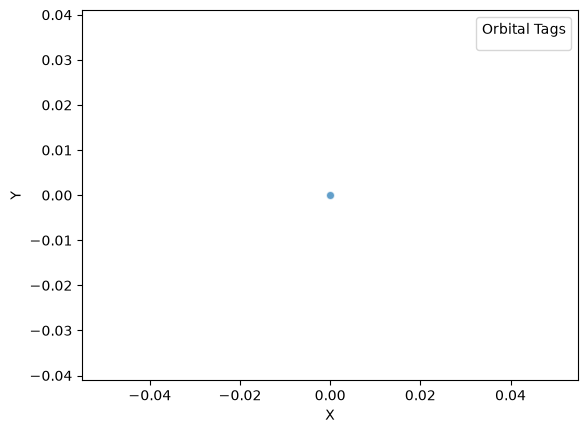

In [6]:
# Lattice constant and vectors are the same in both approaches
lattice_constant = 2.62 # Å
lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 

# OPTION 1 - David's (advanced) goldene definition, includes overlap matrix (non-orthogonal orbitals)
# hopping and overlap values are based on the file from DFTB (Au-Au.skf file)
sk_file = "../../data/Au-Au.skf"
goldene_DD = (Material("goldene")
           .lattice_constant(lattice_constant)  # use 2.62 Å (exp) or 2.735 Å (DFT relaxed)
           .lattice_basis(lattice_basis)
           .add_atom(atom = "Au", position=(0, 0), orbitals = ["s"])  # one Au atom per primitive cell (P6/mmm)
           .add_slater_koster_interaction("Au", "Au", sk_file, num_neighbors = 20)
           )

flake = goldene_DD .cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)
flake.show_2d()

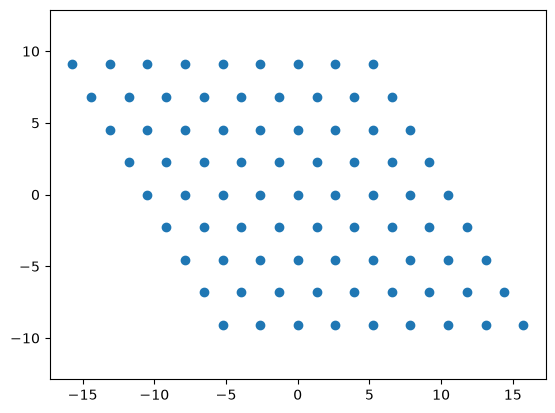

In [7]:
# Define a periodic bulk structure based on the unit cell with one atom

lattice_constant = 2.62
lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])
fourier_cutoff = 4

bulk = Periodic(flake, lattice_vectors, fourier_cutoff)
bulk.show_2d(4)

A: [2.39816233 1.38457967 0.        ]
B: [-0.          2.76915933  0.        ]


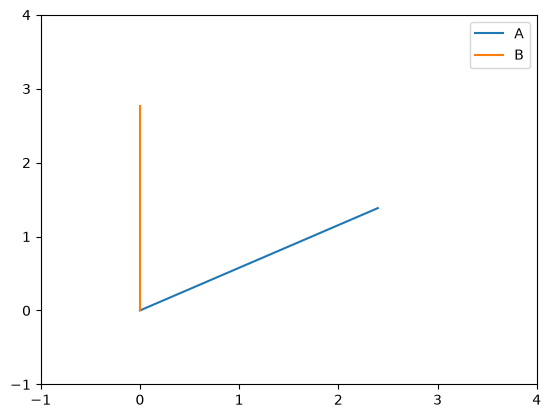

In [8]:
### Calculate reciprocal basis vectors and plot them 

A, B = bulk.reciprocal_basis.T

A_norm = jnp.linalg.norm(A)
B_norm = jnp.linalg.norm(B)
print(f"A: {A}")
print(f"B: {B}")

plt.plot([0, A[0]], [0,A[1]], label="A")
plt.plot([0, B[0]], [0,B[1]], label="B")
ax = plt.gca()
ax.set_xlim([-1, 4])
ax.set_ylim([-1, 4])
plt.legend()
plt.show()

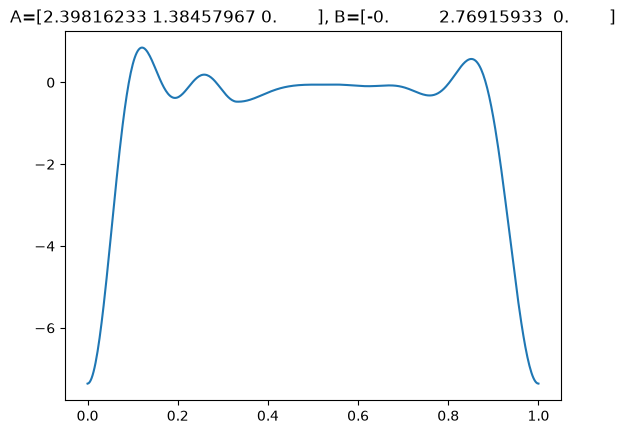

In [9]:
### Plot goldene's band structure along its high-symmetry path in k-space

# Define the path GAMMA -> M -> K -> GAMMA in reciprocal space
ks = jnp.concatenate(
    ( jnp.expand_dims(
          jnp.linspace(0,1/2,150),1)*A,  # Gamma -> M
      jnp.expand_dims(
          jnp.linspace(1/2,1/3,100),1)*A
          + jnp.expand_dims(jnp.linspace(0,1/3,100),1)*B, # M -> K
        jnp.expand_dims(
          jnp.linspace(1/3,0,200),1)*A
          + jnp.expand_dims(jnp.linspace(1/3,0,200),1)*B, # K -> Gamma
    )).T

# Get eigenvalues along the path and plot
energies, eigenvectors = bulk.get_eigenbasis(ks)
plt.plot(jnp.linspace(0, 1, ks.shape[1]), energies)
plt.title(f"A={A}, B={B}")
plt.show()

